CARREGANDO OS PACOTES E O BANCO:

In [10]:
library(splines); library(mgcv)

dados <- read.csv("/content/exportacao_cargas.csv.gz",
                  stringsAsFactors = FALSE, check.names = FALSE)
dim(dados)

[1] 1097014      16

FILTRANDO CARGA CONTEINERIZADA E MONTANDO y, x1, x2 E x3:

In [11]:
dados$TOTAL_TONELADAS <- as.numeric(gsub(",", ".", dados$TOTAL_TONELADAS))
dados_reg <- subset(dados, NATUREZA_CARGA == "CARGA CONTEINERIZADA")
dados_reg$TOTAL_TEU  <- as.numeric(dados_reg$TOTAL_TEU)
dados_reg$TOTAL_UNID <- as.numeric(dados_reg$TOTAL_UNID)
dados_reg$ANO        <- as.numeric(dados_reg$ANO)

set.seed(1)
dados_reg <- dados_reg[sample(nrow(dados_reg), min(50000, nrow(dados_reg))), ]

d <- na.omit(data.frame(y  = dados_reg$TOTAL_TONELADAS,
                        x1 = dados_reg$TOTAL_TEU,
                        x2 = dados_reg$TOTAL_UNID,
                        x3 = dados_reg$ANO))
d <- d[is.finite(rowSums(d)), ]
dim(d)
sapply(d[, c("x1", "x2", "x3")], function(v) length(unique(v)))

[1] 50000     4

x1   x2   x3 
1429  982   22

VALIDAÇÃO CRUZADA DE 5 DOBRAS:

In [12]:
set.seed(1); dobra <- sample(rep(1:5, length = nrow(d)))

cv_de <- function(ajusta) mean(sapply(1:5, function(j) {
  tr <- d[dobra != j, ]; va <- d[dobra == j, ]
  mean((va$y - ajusta(tr, va))^2)
}))

LINHA DE BASE E MQO (JÁ COM A VALIDAÇÃO CRUZADA DENTRO)

In [13]:
set.seed(1); dobra <- sample(rep(1:5, length = nrow(d)))

cv_de <- function(ajusta) mean(sapply(1:5, function(j) {
  tr <- d[dobra != j, ]; va <- d[dobra == j, ]
  mean((va$y - ajusta(tr, va))^2)
}))

cv_base <- cv_de(function(tr, va) mean(tr$y))
cv_mqo  <- cv_de(function(tr, va) predict(lm(y ~ x1 + x2 + x3, data = tr), va))
c(base = cv_base, mqo = cv_mqo)

base     mqo 
5363422 1308404

SPLINE NATURAL NO x1, VARRENDO O df:

In [14]:
dfs <- 2:8
cv_spl <- sapply(dfs, function(k)
  cv_de(function(tr, va) predict(lm(y ~ ns(x1, df = k) + x2 + x3, data = tr), va)))
setNames(round(cv_spl), dfs)

2       3       4       5       6       7       8 
1306356 1304229 1303727 1303751 1303977 1304236 1304505

GAM, OS edf E A FIGURA DAS CURVAS:

s(x1) s(x2) s(x3) 
 9.00  8.66  5.64

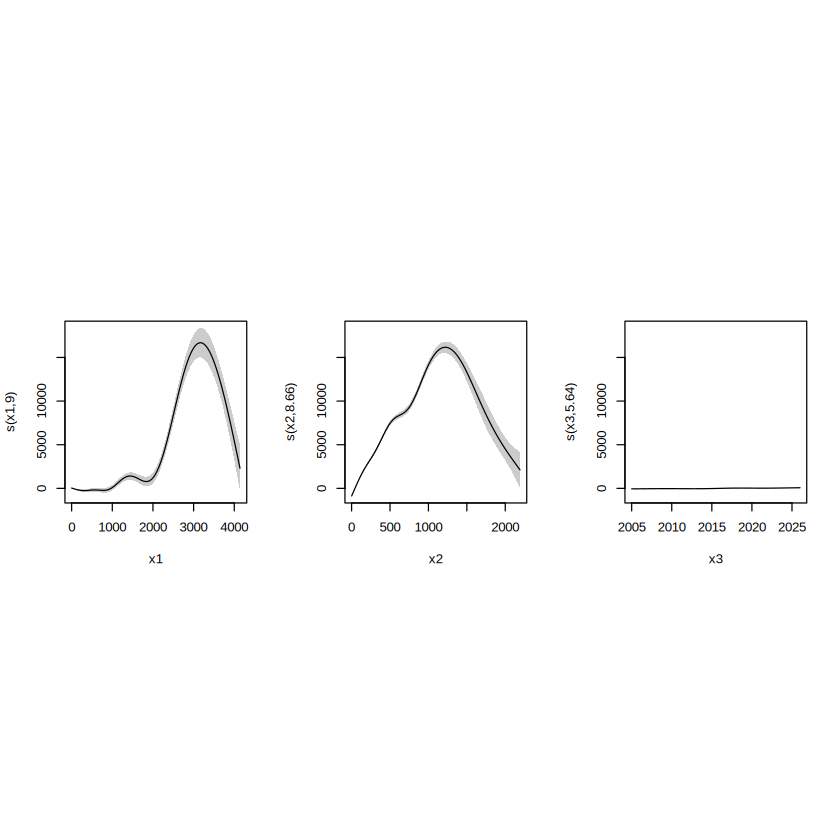

In [15]:
g <- gam(y ~ s(x1) + s(x2) + s(x3), data = d)
round(summary(g)$s.table[, "edf"], 2)
par(mfrow = c(1, 3), pty = "s"); plot(g, scheme = 1)

SPLINE NATURAL, CV DO GAM E O PLACAR (TUDO JUNTO):

In [16]:
dfs <- 2:8
cv_spl <- sapply(dfs, function(k)
  cv_de(function(tr, va) predict(lm(y ~ ns(x1, df = k) + x2 + x3, data = tr), va)))
setNames(round(cv_spl), dfs)

cv_gam <- cv_de(function(tr, va) predict(gam(y ~ s(x1) + s(x2) + s(x3), data = tr), va))

placar <- data.frame(
  metodo = c("linha de base", "MQO",
             paste0("spline natural df=", dfs[which.min(cv_spl)]), "GAM"),
  CV5    = c(cv_base, cv_mqo, min(cv_spl), cv_gam))
placar$RMSE <- round(sqrt(placar$CV5), 1)
placar$CV5  <- round(placar$CV5)
placar

2       3       4       5       6       7       8 
1306356 1304229 1303727 1303751 1303977 1304236 1304505

metodo,CV5,RMSE
<chr>,<dbl>,<dbl>
linha de base,5363422,2315.9
MQO,1308404,1143.9
spline natural df=4,1303727,1141.8
GAM,1283730,1133.0


LEITURA AUTOMÁTICA PARA A FRASE E PARA A RESPOSTA BINÁRIA:

In [17]:
edf <- summary(g)$s.table[, "edf"]
data.frame(preditor = c("x1", "x2", "x3"), edf = round(edf, 2),
           leitura = ifelse(edf < 1.5, "reta", "curva"))
cat("GAM bate a linha de base?", cv_gam < cv_base,
    "| RMSE cai", round(100 * (1 - sqrt(cv_gam) / sqrt(cv_base)), 1), "%\n")
cat("GAM bate o MQO?", cv_gam < cv_mqo, "\n")

,preditor,edf,leitura
,<chr>,<dbl>,<chr>
s(x1),x1,9.00,curva
s(x2),x2,8.66,curva
s(x3),x3,5.64,curva


GAM bate a linha de base? TRUE | RMSE cai 51.1 %
GAM bate o MQO? TRUE 


QUAIS VARIÁVEIS CONTRIBUEM: GAM TIRANDO UMA DE CADA VEZ:

In [18]:
nomes <- c(x1 = "TOTAL_TEU", x2 = "TOTAL_UNID", x3 = "ANO")
cv_sem <- sapply(names(nomes), function(v) {
  f <- as.formula(paste("y ~", paste0("s(", setdiff(names(nomes), v), ")", collapse = " + ")))
  cv_de(function(tr, va) predict(gam(f, data = tr), va))
})
contrib <- data.frame(variavel_retirada = nomes[names(cv_sem)],
                      RMSE_sem = round(sqrt(cv_sem), 1),
                      RMSE_completo = round(sqrt(cv_gam), 1),
                      piora_pct = round(100 * (sqrt(cv_sem) / sqrt(cv_gam) - 1), 1))
contrib[order(-contrib$piora_pct), ]

,variavel_retirada,RMSE_sem,RMSE_completo,piora_pct
,<chr>,<dbl>,<dbl>,<dbl>
x2,TOTAL_UNID,1171.3,1133,3.4
x1,TOTAL_TEU,1134.5,1133,0.1
x3,ANO,1133.5,1133,0.0


CADA VARIÁVEL SOZINHA E A CORRELAÇÃO ENTRE TEU E UNID:

In [19]:
cor(d$x1, d$x2)

cv_so <- sapply(names(nomes), function(v)
  cv_de(function(tr, va) predict(gam(as.formula(paste0("y ~ s(", v, ")")), data = tr), va)))
so <- data.frame(so_com = nomes[names(cv_so)], RMSE = round(sqrt(cv_so), 1),
                 RMSE_base = round(sqrt(cv_base), 1),
                 melhora_pct = round(100 * (1 - sqrt(cv_so) / sqrt(cv_base)), 1))
so[order(-so$melhora_pct), ]

[1] 0.9842758

,so_com,RMSE,RMSE_base,melhora_pct
,<chr>,<dbl>,<dbl>,<dbl>
x2,TOTAL_UNID,1135.0,2315.9,51.0
x1,TOTAL_TEU,1171.5,2315.9,49.4
x3,ANO,2309.3,2315.9,0.3
